In [30]:
import os.path

import pandas as pd
from glob import glob
import re
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import json
import torch
import numpy as np
from bbox_annotation import Annotation, annotation_from_json
from sklearn.model_selection import train_test_split
import cv2

import matplotlib.pyplot as plt
from tool import crop_rgb

In [31]:
%store -r data_df

In [32]:
data_df

,Name,Image,Image Width,Image Height,Depth Column,Interpreted Lithology Column,Lithology Legend
0,MC765_P011_ST00BP00_5inchMD_Depth_MudLog_3686-...,/home/trip/PycharmProjects/HTB/dataset/images/...,1700,176000,"[377, 1623, 448, 174871]","[1134, 1623, 1171, 174871]","[79, 904, 1621, 1327]"
1,Mudlog-Trail Mtn1Palisades,/home/trip/PycharmProjects/HTB/dataset/images/...,1650,62325,"[391, 1424, 414, 62325]","[335, 1424, 391, 62325]","[75, 691, 673, 1215]"
2,Shell_AC0336_OCS-G-36102_001_ST00BP01_5inchMD_...,/home/trip/PycharmProjects/HTB/dataset/images/...,1275,143550,"[340, 1129, 400, 142323]","[400, 1129, 450, 142323]","[30, 668, 1208, 832]"
3,60817410140100_mc822#10bp01 1-240 tvd mud log,/home/trip/PycharmProjects/HTB/dataset/images/...,1534,163220,"[236, 1205, 316, 163204]","[953, 1205, 1000, 163204]","[2, 594, 1532, 1000]"
4,0000000009_d-582_0000020435-0001_log06_fe_5in_md,/home/trip/PycharmProjects/HTB/dataset/images/...,4864,12050,"[1288, 4404, 1376, 11195]","[2991, 4404, 3237, 11195]","[1943, 1513, 3035, 2655]"
5,60811405800300_mdn-1_st01bp01_5 inch tvdmudlog...,/home/trip/PycharmProjects/HTB/dataset/images/...,1275,120450,"[265, 1185, 325, 119853]","[932, 1185, 980, 119853]","[60, 452, 1210, 768]"
6,60817411400100_mc761_1_st1_mudlog_1tvd_17129_2...,/home/trip/PycharmProjects/HTB/dataset/images/...,1275,8250,"[255, 2197, 288, 8198]","[938, 2197, 995, 8198]","[0, 972, 918, 1400]"
7,MC765_P011_ST00BP01_5inchMD_Depth_MudLog_18230...,/home/trip/PycharmProjects/HTB/dataset/images/...,1700,35200,"[377, 1623, 448, 33669]","[1134, 1623, 1171, 33669]","[79, 904, 1621, 1327]"
8,60811406050000_608114060500_g31765 001 st00 bp...,/home/trip/PycharmProjects/HTB/dataset/images/...,1680,238000,"[278, 1628, 343, 233912]","[1167, 1628, 1230, 233912]","[2, 600, 1538, 1021]"
9,60811405800100_mdn-1_st00bp01_5 inch tvdmudlog...,/home/trip/PycharmProjects/HTB/dataset/images/...,1534,187600,"[275, 1575, 355, 187576]","[1165, 1575, 1228, 187576]","[2, 599, 1532, 1002]"


In [33]:
example_row = data_df[data_df["Name"]=="60817411400100_mc761_1_st1_mudlog_1tvd_17129_20968"].iloc[0]

In [34]:
colbounds = example_row["Interpreted Lithology Column"]

In [35]:
column = crop_rgb(Image.open(example_row["Image"]), colbounds)

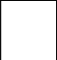

5.116959064327485 % of pixels are black


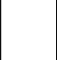

3.508771929824561 % of pixels are black


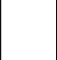

3.508771929824561 % of pixels are black


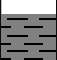

15.263157894736842 % of pixels are black


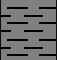

17.485380116959064 % of pixels are black


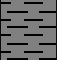

19.1812865497076 % of pixels are black


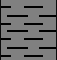

16.95906432748538 % of pixels are black


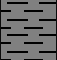

18.333333333333332 % of pixels are black


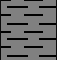

18.333333333333332 % of pixels are black


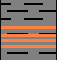

12.456140350877194 % of pixels are black


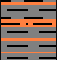

18.128654970760234 % of pixels are black


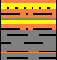

16.198830409356727 % of pixels are black


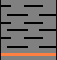

15.263157894736842 % of pixels are black


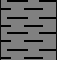

19.1812865497076 % of pixels are black


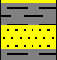

13.099415204678364 % of pixels are black


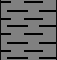

19.1812865497076 % of pixels are black


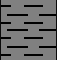

16.95906432748538 % of pixels are black


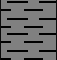

19.1812865497076 % of pixels are black


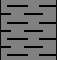

17.485380116959064 % of pixels are black


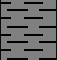

19.1812865497076 % of pixels are black


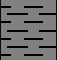

16.95906432748538 % of pixels are black


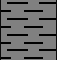

19.1812865497076 % of pixels are black


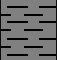

17.485380116959064 % of pixels are black


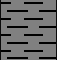

19.1812865497076 % of pixels are black


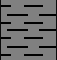

16.95906432748538 % of pixels are black


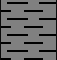

19.1812865497076 % of pixels are black


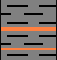

15.789473684210526 % of pixels are black


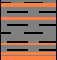

14.94152046783626 % of pixels are black


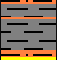

19.093567251461987 % of pixels are black


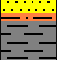

17.485380116959064 % of pixels are black


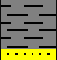

16.023391812865498 % of pixels are black


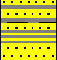

8.538011695906434 % of pixels are black


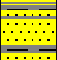

10.701754385964913 % of pixels are black


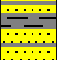

10.935672514619883 % of pixels are black


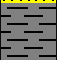

17.894736842105264 % of pixels are black


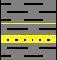

16.023391812865498 % of pixels are black


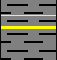

17.485380116959064 % of pixels are black


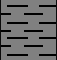

17.485380116959064 % of pixels are black


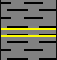

18.596491228070175 % of pixels are black


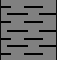

16.95906432748538 % of pixels are black


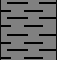

19.1812865497076 % of pixels are black


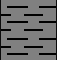

17.485380116959064 % of pixels are black


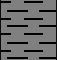

19.1812865497076 % of pixels are black


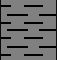

16.95906432748538 % of pixels are black


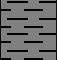

19.1812865497076 % of pixels are black


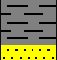

15.146198830409357 % of pixels are black


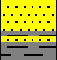

12.456140350877194 % of pixels are black


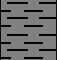

19.1812865497076 % of pixels are black


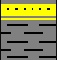

14.327485380116958 % of pixels are black


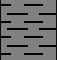

16.95906432748538 % of pixels are black


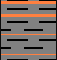

15.789473684210526 % of pixels are black


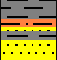

15.058479532163743 % of pixels are black


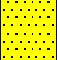

9.824561403508772 % of pixels are black


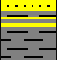

14.327485380116958 % of pixels are black


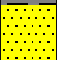

11.228070175438596 % of pixels are black


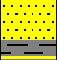

11.403508771929824 % of pixels are black


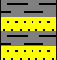

14.502923976608187 % of pixels are black


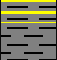

16.900584795321638 % of pixels are black


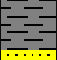

17.13450292397661 % of pixels are black


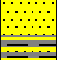

11.900584795321638 % of pixels are black


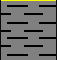

17.485380116959064 % of pixels are black


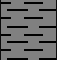

19.1812865497076 % of pixels are black


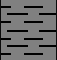

16.95906432748538 % of pixels are black


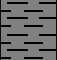

19.1812865497076 % of pixels are black


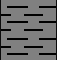

17.485380116959064 % of pixels are black


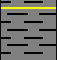

16.95906432748538 % of pixels are black


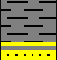

15.175438596491228 % of pixels are black


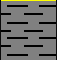

17.485380116959064 % of pixels are black


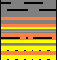

10.526315789473683 % of pixels are black


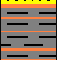

14.473684210526317 % of pixels are black


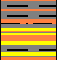

11.345029239766081 % of pixels are black


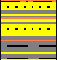

9.53216374269006 % of pixels are black


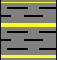

13.567251461988302 % of pixels are black


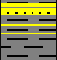

15.964912280701753 % of pixels are black


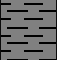

18.070175438596493 % of pixels are black


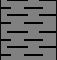

18.070175438596493 % of pixels are black


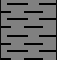

19.1812865497076 % of pixels are black


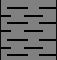

17.485380116959064 % of pixels are black


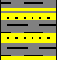

12.865497076023392 % of pixels are black


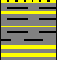

12.631578947368421 % of pixels are black


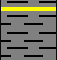

17.485380116959064 % of pixels are black


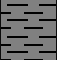

18.333333333333332 % of pixels are black


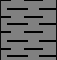

18.333333333333332 % of pixels are black


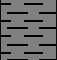

18.070175438596493 % of pixels are black


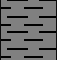

18.070175438596493 % of pixels are black


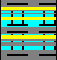

15.906432748538013 % of pixels are black


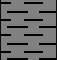

19.1812865497076 % of pixels are black


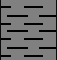

16.95906432748538 % of pixels are black


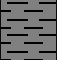

18.333333333333332 % of pixels are black


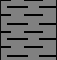

18.333333333333332 % of pixels are black


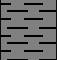

18.070175438596493 % of pixels are black


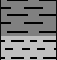

18.30409356725146 % of pixels are black


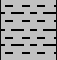

16.08187134502924 % of pixels are black


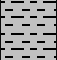

18.24561403508772 % of pixels are black


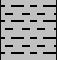

16.72514619883041 % of pixels are black


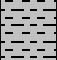

18.24561403508772 % of pixels are black


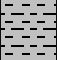

16.08187134502924 % of pixels are black


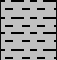

18.24561403508772 % of pixels are black


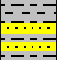

15.204678362573098 % of pixels are black


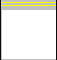

3.508771929824561 % of pixels are black


In [42]:
x, y = column.size
top = 0
bounding = y // 100
def is_black(rgb, threshold=50):
    r, g, b = rgb[:3]
    luma = 0.299 * r + 0.587 * g + 0.114 * b
    return luma < threshold
for bottom in range(bounding, y+1, bounding):
    box = column.crop( (0, top, x, bottom) )
    display(box)
    w = box.size[0]
    h = box.size[1]
    pixels = box.load()
    counter = 0
    for by in range(h):
        for bx in range(w):
            if is_black(pixels[bx, by]):
                counter += 1
    print(counter / (bounding*x) * 100, "% of pixels are black")
    top += bounding


